In [1]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [2]:
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_cluster_bar_strip_sidebyside(panels, order_by='performance', min_n=5,
                                      panel_width=3.6, save_path=None):

    ref = next(p for p in panels if p['metric'] == order_by)
    keep = ref['s'][ref['s']['matched_n'] >= min_n]
    order = keep.sort_values(f'{order_by}_median', ascending=False)['best_description'].tolist()
    n_by = keep.set_index('best_description')['matched_n']

    cmap = plt.get_cmap('tab20')
    palette = {n: cmap(i % 20) for i, n in enumerate(
        keep.sort_values('cluster_id')['best_description'])}
    ypos = np.arange(len(order))

    fig, axes = plt.subplots(1, len(panels), sharey=True,
                             figsize=(panel_width * len(panels), 0.4*len(order)))
    for k, (ax, p) in enumerate(zip(np.atleast_1d(axes), panels)):
        m = p['metric']
        sm = p['s'].set_index('best_description').loc[order]
        med, q1, q3 = sm[f'{m}_median'].values, sm[f'{m}_Q1'].values, sm[f'{m}_Q3'].values
        colors = [palette[n] for n in order]

        ax.barh(ypos, med, color=colors, alpha=0.45, edgecolor='none', height=0.7, zorder=1)
        ax.errorbar(med, ypos, xerr=[med - q1, q3 - med], fmt='none',
                    ecolor='black', elinewidth=1, capsize=2, zorder=2)
        sns.stripplot(data=p['long'][p['long']['best_description'].isin(order)], x=m,
                      y='best_description', order=order, orient='h', hue='best_description',
                      palette=palette, legend=False, size=3, jitter=0.25,
                      edgecolor='black', linewidth=0.3, alpha=0.9, ax=ax, zorder=3)
        ax.axvline(p['d'][m].median(), color='grey', ls='--', lw=1, zorder=0)
        ax.axvline(0, color='black', ls='-', lw=1, zorder=0)
        ax.set_xlabel(p['label'])
        ax.set_ylabel('')
        sns.despine(ax=ax)
    axes = np.atleast_1d(axes)
    axes[0].set_yticks(ypos)
    axes[0].set_yticklabels([f'{n} (n={n_by[n]})' for n in order])
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, bbox_inches='tight')
    plt.show()
    return fig


In [ ]:
i=1 # K562 Essential

results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{analysis_targets[i].lower()}/detailed_metrics.csv')
predictive_performance = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
predictive_performance['perturbation'] = predictive_performance['perturbation'].apply(lambda x: x.split('_')[-1])
predictive_performance = predictive_performance[['perturbation', 'value']]
predictive_performance = predictive_performance.set_index('perturbation')
joint_perts = list(prior_intrinsic_scores.index.intersection(predictive_performance.index))
predictive_performance = predictive_performance.loc[joint_perts]
prior_agreement = prior_intrinsic_scores.loc[joint_perts].mean(axis=1)
cofunc_scores = (gene_level_global_metrics[analysis_targets[i]]+gene_level_local_metrics[analysis_targets[i]])/2
cofunc_agreement = cofunc_scores.loc[joint_perts].mean(axis=1)

c = pd.read_excel('/home/jhpark/page_reproducibility/05_forecastability/intermediate/replogle_22_clusters.xlsx',sheet_name='perturbation clusters')
p = predictive_performance.reset_index().rename(columns={'perturbation':'gene','value':'performance'})
a = prior_agreement.reset_index().rename(columns={0:'Aprior'})

for d in (p,a):
    d['gene'] = d.gene.astype(str).str.strip().str.upper()
d = p.merge(a, on='gene', validate='one_to_one')

assert len(d)==len(p)==len(a)

rows=[]
summaries=[]
unmatched=[]

for _ , r in c.iterrows():
 cid = int(r['Unnamed: 0'])
 desc =str(r.best_description)
 members=sorted(set(g.strip().upper() for g in str(r.members).split(',') if g.strip()))

 x = d[d.gene.isin(members)].copy()
 x['cluster_id'] = cid
 x['best_description'] = desc
 rows.append(x)

 s={
   'cluster_id':cid,
   'best_description':desc,
   'listed_n':len(members),
   'matched_n':len(x),
   'matching_fraction':len(x)/len(members)
}

 for score in ['Aprior','performance']:
  for lab,func in [('median',lambda v:v.median()),('Q1',lambda v:v.quantile(.25)),('Q3',lambda v:v.quantile(.75)),('mean',lambda v:v.mean()),('min',lambda v:v.min()),('max',lambda v:v.max())]:
   s[f'{score}_{lab}']=func(x[score])

 s['matched_genes']=','.join(sorted(x.gene))
 summaries.append(s)

 for g in sorted(set(members)-set(d.gene)):
   unmatched.append({'cluster_id':cid,'best_description':desc,'gene':g})

long = pd.concat(rows,ignore_index=True)
s = pd.DataFrame(summaries)
covered = set(long.gene)
ref = d[~d.gene.isin(covered)].copy()
ref['cluster_id']=-1
ref['best_description']='Not assigned in supplied clusters'

long_prior, s_prior, d_prior = long.copy(), s.copy(), d.copy()

p=predictive_performance.reset_index().rename(columns={'perturbation':'gene','value':'performance'})
a=cofunc_agreement.reset_index().rename(columns={0:'Acofunc'})

for d in (p,a):
    d['gene'] = d.gene.astype(str).str.strip().str.upper()
d = p.merge(a, on='gene', validate='one_to_one')

assert len(d)==len(p)==len(a)

rows = []
summaries = []
unmatched = []

for _, r in c.iterrows():
 cid = int(r['Unnamed: 0'])
 desc = str(r.best_description)
 members = sorted(set(g.strip().upper() for g in str(r.members).split(',') if g.strip()))

 x = d[d.gene.isin(members)].copy()
 x['cluster_id'] = cid
 x['best_description']=desc
 rows.append(x)

 s={
   'cluster_id':cid,
   'best_description':desc,
   'listed_n':len(members),
   'matched_n':len(x),
   'matching_fraction':len(x)/len(members)
}

 for score in ['Acofunc','performance']:
  for lab,func in [('median',lambda v:v.median()),('Q1',lambda v:v.quantile(.25)),('Q3',lambda v:v.quantile(.75)),('mean',lambda v:v.mean()),('min',lambda v:v.min()),('max',lambda v:v.max())]:
   s[f'{score}_{lab}']=func(x[score])

 s['matched_genes']=','.join(sorted(x.gene))
 summaries.append(s)

 for g in sorted(set(members)-set(d.gene)):
   unmatched.append({'cluster_id':cid,'best_description':desc,'gene':g})

long = pd.concat(rows,ignore_index=True)
s = pd.DataFrame(summaries)
covered = set(long.gene)
ref = d[~d.gene.isin(covered)].copy()
ref['cluster_id']=-1
ref['best_description']='Not assigned in supplied clusters'

long_cofunc, s_cofunc, d_cofunc = long.copy(), s.copy(), d.copy()

/tmp/ipykernel_3452765/2089410714.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  predictive_performance = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']


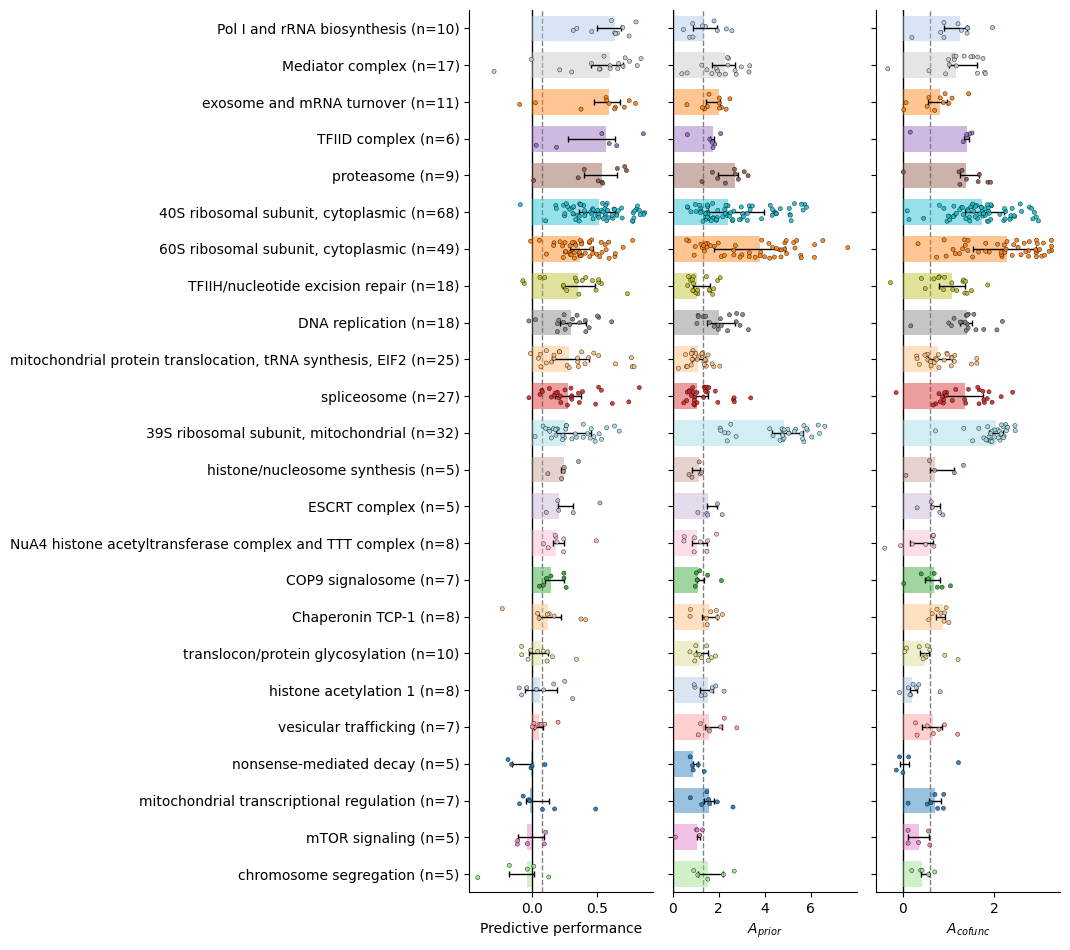

In [5]:
fig = plot_cluster_bar_strip_sidebyside([
    dict(long=long_prior,  s=s_prior,  d=d_prior,  metric='performance', label='Predictive performance'),
    dict(long=long_prior,  s=s_prior,  d=d_prior,  metric='Aprior',      label='$A_{prior}$'),
    dict(long=long_cofunc, s=s_cofunc, d=d_cofunc, metric='Acofunc',     label='$A_{cofunc}$'),
], order_by='performance', min_n=5)
#fig.savefig('./figure_out/figS5_by_pathway.pdf')